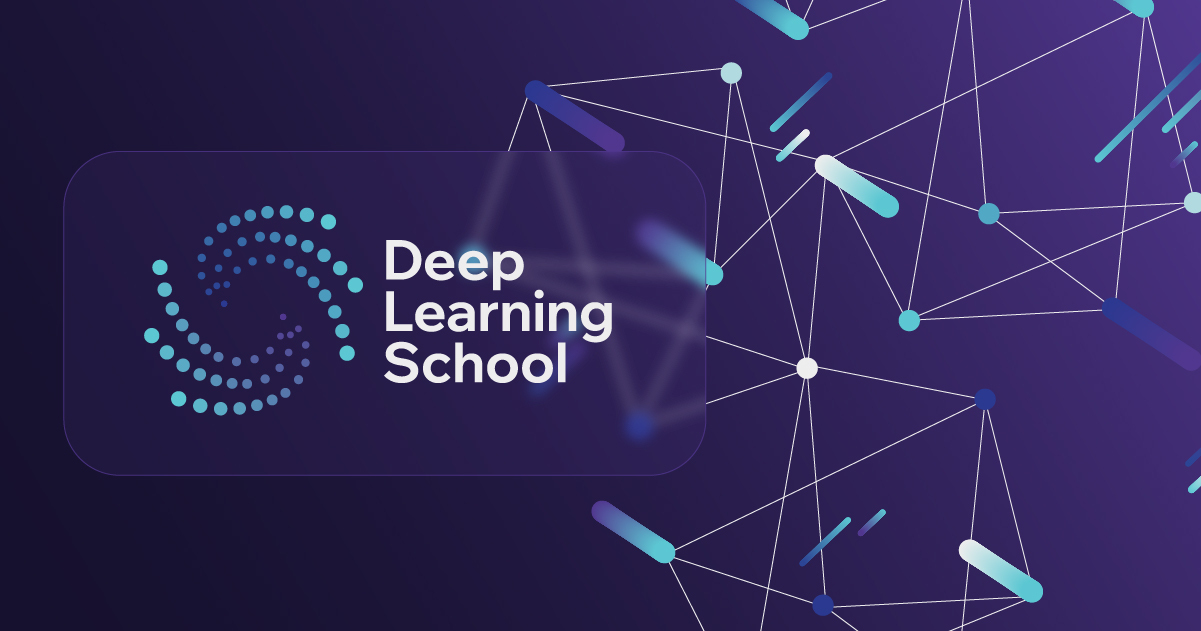


<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h3 style="text-align: center;"><b>Домашнее задание. Классификация изображений</b></h3>


# Домашнее задание. Классификация изображений

Сегодня вам предстоить помочь телекомпании FOX в обработке их контента. Как вы знаете, сериал "Симпсоны" идет на телеэкранах более 25 лет, и за это время скопилось очень много видеоматериала. Персоонажи менялись вместе с изменяющимися графическими технологиями, и Гомер Симпсон-2018 не очень похож на Гомера Симпсона-1989. В этом задании вам необходимо классифицировать персонажей, проживающих в Спрингфилде. Думаю, нет смысла представлять каждого из них в отдельности.



В нашем тесте будет 991 картинка, для которых вам будет необходимо предсказать класс.

## Шаг 1. Установка зависимостей

### Установим необходимые библиотеки и проверим доступность CUDA

In [34]:
# we will verify that GPU is enabled for this notebook
# following should print: CUDA is available!  Training on GPU ...
#
# if it prints otherwise, then you need to enable GPU:
# from Menu > Runtime > Change Runtime Type > Hardware Accelerator > GPU

import torch
import numpy as np
train_on_gpu = torch.cuda.is_available()

if not train_on_gpu:
    print('CUDA is not available.  Training on CPU ...')
else:
    print('CUDA is available!  Training on GPU ...')

CUDA is available!  Training on GPU ...


In [35]:
!nvidia-smi

Wed Aug 26 08:31:20 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P0             30W /   70W |     159MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [36]:
import pickle
import numpy as np
from skimage import io

from tqdm import tqdm, tqdm_notebook
from PIL import Image
from pathlib import Path

from torchvision import transforms
from torchvision.transforms import v2

import torchsummary

from multiprocessing.pool import ThreadPool
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

from matplotlib import colors, pyplot as plt
%matplotlib inline

# в sklearn не все гладко, чтобы в colab удобно выводить картинки
# мы будем игнорировать warnings
import warnings
warnings.filterwarnings(action='ignore', category=DeprecationWarning)


#### Проверим версии Python и библиотек
Посмотрим, какие версии установлены:

In [37]:
!python --version
from importlib.metadata import version
for b in ['torch', 'torchvision', 'tqdm', 'matplotlib', 'seaborn', 'Pillow']:
    print(b + ' version: '+ version(b))

Python 3.13.15
torch version: 2.11.0+cu128
torchvision version: 0.26.0+cu128
tqdm version: 4.67.3
matplotlib version: 3.10.0
seaborn version: 0.13.2
Pillow version: 11.3.0


Сверим с версиями питона и библиотек, на которых работал эталонный ноутбук:

- Python 3.12.12
- torch version: 2.8.0+cu126
- torchvision version: 0.23.0+cu126
- tqdm version: 4.67.1
- matplotlib version: 3.10.0
- seaborn version: 0.13.2
- Pillow version: 11.3.0


 #### Определим константы, которые будем использовать в по ходу ноутбука

In [38]:
# разные режимы датасета
DATA_MODES = ['train', 'val', 'test']

# работаем на видеокарте

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#определим директории с тренировочными и тестовыми файлами
TRAIN_DIR = Path('/content/train') #Path('./data/train/')
TEST_DIR = Path('/content/testset') #Path('./data/testset')

# параметры нормировки изображений по трем каналам перед подачей в модель
NORMALIZE_MEAN = [0.485, 0.456, 0.406]
NORMALIZE_STD = [0.229, 0.224, 0.225]

# все изображения будут масштабированы к размеру 224x224 px
RESCALE_SIZE = [224, 224]

### Рабочая папка на drive для сохранения весов

In [65]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

weights_folder = Path('/content/drive/MyDrive/dls/dls_part_1/weights/hw_5/')
weights_folder.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Шаг 2. Загрузка и обработка данных

#### Скачаем изображения по ссылке

#### Скачаем данные из соревнования на Kaggle

Ссылка на Google Drive пропала, поэтому данные берём напрямую из соревнования `journey-to-springfield1` на Kaggle. Для этого нужен файл `kaggle.json` (загрузите его в корень `/content` через панель Files в Colab).

In [40]:
# Установка Kaggle CLI
!pip install -q kaggle

import os
import json

# Создаём kaggle.json прямо в /content (и в ~/.kaggle) из данных ниже.
# Это надёжнее, чем загружать файл через панель Files.
KAGGLE_CREDENTIALS = {
    "username": "libertman",
    "key": "6160750a77fadb967f7a70e619335de0"
}

# 1) Кладём kaggle.json в /content (на случай, если понадобится)
with open('/content/kaggle.json', 'w') as f:
    json.dump(KAGGLE_CREDENTIALS, f)

# 2) Кладём kaggle.json туда, где его ищет Kaggle CLI: ~/.kaggle/kaggle.json
os.makedirs(os.path.expanduser('~/.kaggle'), exist_ok=True)
with open(os.path.expanduser('~/.kaggle/kaggle.json'), 'w') as f:
    json.dump(KAGGLE_CREDENTIALS, f)
os.chmod(os.path.expanduser('~/.kaggle/kaggle.json'), 0o600)

print('kaggle.json создан в /content и ~/.kaggle')
print('Проверка подключения:')
!kaggle competitions list -s journey-to-springfield1

kaggle.json создан в /content и ~/.kaggle
Проверка подключения:
ref                                                          deadline             category   reward  teamCount  userHasEntered  
-----------------------------------------------------------  -------------------  ---------  ------  ---------  --------------  
https://www.kaggle.com/competitions/journey-to-springfield1  2026-10-12 15:20:00  Community   Kudos        843            True  


In [41]:
# Проверяем, скачаны ли уже данные: в /content/train должны быть папки классов с jpg,
# а в /content/testset — изображения. Если всё на месте, скачивание пропускается.
def data_is_ready(train_dir, test_dir):
    train_ok = train_dir.exists() and any(train_dir.rglob('*.jpg'))
    test_ok = test_dir.exists() and any(test_dir.rglob('*.jpg'))
    return train_ok and test_ok

TRAIN_DIR = Path('/content/train')
TEST_DIR = Path('/content/testset')

if data_is_ready(TRAIN_DIR, TEST_DIR):
    print('Данные уже скачаны, пропускаем загрузку.')
else:
    # Скачиваем все файлы соревнования (train + testset + sample_submission)
    !kaggle competitions download -c journey-to-springfield1 -p /content

    # Распаковываем архив
    !unzip -q /content/journey-to-springfield1.zip -d /content

    # Приводим структуру к ожидаемой ноутбуком:
    #   train/simpsons_dataset/<класс>/*.jpg  ->  train/<класс>/*.jpg
    #   testset/testset/*.jpg                 ->  testset/*.jpg
    !mv /content/train/simpsons_dataset/* /content/train/
    !rmdir /content/train/simpsons_dataset
    !mv /content/testset/testset/* /content/testset/
    !rmdir /content/testset/testset

print('Данные готовы:')
!ls /content/train | head -5
print('...')
!ls /content/testset | head -5

Данные уже скачаны, пропускаем загрузку.
Данные готовы:
abraham_grampa_simpson
agnes_skinner
apu_nahasapeemapetilon
barney_gumble
bart_simpson
...
img0.jpg
img100.jpg
img101.jpg
img102.jpg
img103.jpg


Посмотрите на структуру файлов в папках train и testset.

В train лежат данные, которые мы будем использовать для обучения модели. Изображения персонажей разложены по папкам, которые названы по именам персонажей. Названия папок мы в дальнейшем будет использовать в качестве текстовых меток классов.

В testset находятся изображения, для которых вам надо будет сделать прогноз наиболее вероятного класса.


Для обращения к файлам сформируем списки имен файлов обучающей+валидационнной и тестовой выборок. Это полные имена, включающие путь к файлам.


In [42]:
train_val_files = sorted(list(TRAIN_DIR.rglob('*.jpg')))
test_files = sorted(list(TEST_DIR.rglob('*.jpg')))

Кодировать имена персонажей в числовые метки класса и обратно будем при помощи `LabelEncoder`.

Для train выборки сформируем список текстовых меток всех изображений - имя родительской директории, которая одновременно является и именем персонажа. Зададим числовые метки классов нашего энкодера при помощи метода `fit`.

Далее будем применять метод `transform` для преобразования текстовых меток в числовые, и метод `inverse_transform` для преобразования числовых меток в текстовые.


In [43]:
label_encoder = LabelEncoder()

train_val_labels = [path.parent.name for path in train_val_files]

label_encoder.fit(train_val_labels)

LabelEncoder()

Разделим train выборку на обучающую и валидационнную части. Для того, чтобы персонажи были пропорционально представлены в обучающей и валидационнной подвыборках, применим стратификацию по меткам класса.

In [44]:
from sklearn.model_selection import train_test_split

train_files, val_files = train_test_split(train_val_files, test_size=0.25, \
                                          stratify=train_val_labels)

### Создадим Datasets и Dataloaders

Полезная статья, которой мы вдохновились при создании класса `SimpsonsDataset`:
https://jhui.github.io/2018/02/09/PyTorch-Data-loading-preprocess_torchvision/


У нас есть набор файлов-картинок, которые требуется преобразовать в тензоры, и добавить к ним числовые метки классов. Реализуем это с помощью созданного нами класса `SimpsonsDataset`, который из списка файлов создаст необходимый нам Dataset.  

Будем действовать согласно инструкции из документации (https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html#creating-a-custom-dataset-for-your-files):
- наш класс будет наследовать от класса Dataset
- мы переопределим методы `__init__`, `__len__` и `__getitem__`, а также для удобства добавим несколько методов для загрузки и преобразования изображений.

Важно разобраться, что делает метод self.transform_images_to_tensors().

`Compose` объединяет последовательность следующих преобразований:
- `PILToTensor` конвертирует  `PIL Image` в тензор с параметрами в диапазоне $[0, 255]$ (как все пиксели в исходном изображении)
- `ToDtype` преобразует тензор в `FloatTensor` размера ($C \times H \times W$) со значениями пикселей в диапазоне $[0,1]$
- затем `Normalize` производится масштабирование:
$\text{input} = \frac{\text{input} - \text{mean}}{\text{std}} $, <br>      где константы mean и std - средние и дисперсии по каналам в датасете ImageNet
- наконец, `Resize` преобразует картинки к размеру $224 \times 224$ (в описании датасета указано, что картинки разного размера, так как брались напрямую с видео, поэтому следует привести их к одному размеру).

Сейчас аугментация не изображений не производится, поэтому для обучающих и валидационных/тестовых изображений производится одинаковая трансформация. В дальнейшем, если вы захотите добавить аугментацию, вы можете сделать это, например, модифицировав метод `transform_images_to_tensors`. Подробнее про трансформацию изображений вы можете почитать в документации: https://docs.pytorch.org/vision/main/transforms.html


In [45]:
class SimpsonsDataset(Dataset):
    def __init__(self, files, label_encoder, mode):
        super().__init__()
        # список файлов для загрузки
        self.files = sorted(files)
        # режим работы
        self.mode = mode
        if self.mode not in DATA_MODES:
            print(f"{self.mode} is not correct; correct modes: {DATA_MODES}")
            raise NameError

        self.label_encoder = label_encoder
        self.len_ = len(self.files)

    def __len__(self):
        return self.len_ # сейчас self.__len__() возвращает количество картинок, подаваемых на вход.
        # Если вы решите перевзвесить размеры категорий внутри класса -
        # не забудьте изменить вывод self.__len__()

    def __getitem__(self, index):
        x = self.load_image(self.files[index])
        x = self.transform_images_to_tensors(x)

        if self.mode == 'test':
            return x
        else:
            path = self.files[index]
            y = self.label_encoder.transform([path.parent.name,]).item()
            return x, y

    # принимает путь к файлу изображения и возвращает само изображение
    def load_image(self, file):
        image = Image.open(file)
        image.load()
        return image

    # преобразует изображение в тензор
    def transform_images_to_tensors(self, image):
      if self.mode == 'train':
        # Аугментация только для обучающей выборки:
        # - RandomResizedCrop: случайный кроп масштаба 0.8-1.0 -> инвариантность к зумму/кадрированию;
        # - RandomHorizontalFlip: зеркальное отражение -> удваивает объём данных;
        # - RandomAffine: лёгкий поворот/сдвиг/масштаб/наклон -> устойчивость к позе персонажа;
        # - ColorJitter: яркость/контраст/насыщенность -> устойчивость к изменению цвета.
        # Геометрические аугментации выполняются ДО Normalize, на пикселях в диапазоне [0,1].
        transform = v2.Compose([
            v2.PILToTensor(),
            v2.ToDtype(torch.float32, scale=True),
            v2.RandomResizedCrop(RESCALE_SIZE, scale=(0.8, 1.0), ratio=(0.9, 1.1)),
            v2.RandomHorizontalFlip(p=0.5),
            v2.RandomAffine(degrees=8, translate=(0.1, 0.1), scale=(0.9, 1.1), shear=8, fill=0),
            v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
            v2.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
          ])
      else:
        transform = v2.Compose([
            v2.PILToTensor(),
            v2.ToDtype(torch.float32, scale=True),
            v2.Normalize(NORMALIZE_MEAN, NORMALIZE_STD),
            v2.Resize(RESCALE_SIZE),
          ])

      tensor_transformed = transform(image)
      return(tensor_transformed)


In [46]:
# НЕ предзагружаем все тензоры в память: при 224x224 полный датасет занимает ~12.6 ГБ
# оперативки и вызывал краш ядра Colab (RAM ~12.7 ГБ). Оставляем обычный датасет,
# который читает картинки на лету. Ускорение обеспечиваем num_workers=2
train_dataset = SimpsonsDataset(train_files, label_encoder = label_encoder, mode='train')
val_dataset = SimpsonsDataset(val_files, label_encoder, mode='val')

In [47]:
batch_size = 64

In [48]:
# num_workers=2 соответствует числу ядер CPU в этой сессии Colab и не даёт
# предупреждения PyTorch о чрезмерном числе процессов (в отличие от 4).
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, prefetch_factor=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, prefetch_factor=2, pin_memory=True)
loaders = {'train':train_loader, 'val': val_loader}

## Решение проблемы дисбаланса: WeightedRandomSampler

Для компенсации дисбаланса каждому примеру в обучающей выборке присваивается вес $w_i = \frac{1}{N_{class(i)}}$.
Затем `WeightedRandomSampler` формирует батчи так, чтобы вероятность выбора каждого класса была равномерной.

In [49]:
from torch.utils.data.sampler import WeightedRandomSampler

n_classes = len(label_encoder.classes_)
train_labels = [label_encoder.transform([p.parent.name])[0] for p in train_dataset.files]
train_class_counts = np.bincount(train_labels, minlength=n_classes)

# 1. Веса каждого класса обратно пропорциональны числу его объектов
class_weights = 1.0 / train_class_counts

# 2. Веса для каждого элемента датасета
sample_weights = np.array([class_weights[label] for label in train_labels])
sample_weights = torch.from_numpy(sample_weights).double()

# 3. Создаем сбалансированный сэмплер
balanced_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# 4. Пересоздаем train_loader со сэмплером
train_loader_balanced = DataLoader(
    train_dataset,
    batch_size=batch_size,
    sampler=balanced_sampler,
    num_workers=2,
    prefetch_factor=2,
    pin_memory=True
)

loaders["train"] = train_loader_balanced

#### Посмотрим на изображения персонажей

Напишем функцию для визуализации картинок. Это аналог Imshow, которая будет принимать на вход тензоры

In [50]:
def imshow(inp, title=None, plt_ax=plt, default=False):
    """Imshow для тензоров"""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt_ax.imshow(inp)
    if title is not None:
        plt_ax.set_title(title)
    plt_ax.grid(False)

Проверим, как работает наша функция. Возьмем один батч из лоадера и подадим на вход функции первый тензор из этого батча. Заодно посмотрим, как работает кодировщик меток класса.

Числовая метка класса: 28
Текстовая метка класса: ['ned_flanders']


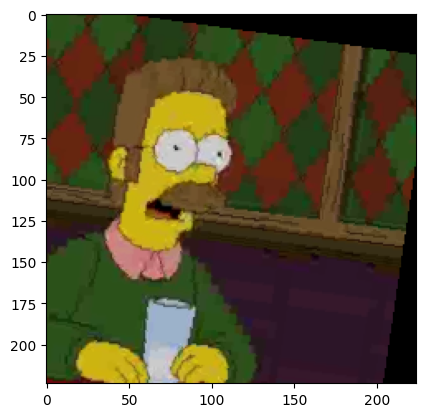

In [51]:
image_tensor, label = next(iter(train_loader))
print(f"Числовая метка класса: {label[0]}")
print(f"Текстовая метка класса: {label_encoder.inverse_transform([label[0],])}")
imshow(image_tensor[0])


In [52]:
# uncomment if you have problem with pillow
# def register_extension(id, extension): Image.EXTENSION[extension.lower()] = id.upper()
# Image.register_extension = register_extension
# def register_extensions(id, extensions):
#     for extension in extensions: register_extension(id, extension)
# Image.register_extensions = register_extensions

Давайте посмотрим на наших героев внутри датасета.

In [53]:
def show_images(n_rows, n_cols, dataset):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, ax = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in ax.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # получаем изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()
    fig_x.set_axis_off()
  return None

**!** Обратите внимание, что возможно, датасет требует дополнительной фильтрации, так как лейблы не всегда точно соответствуют картинкам. Очистка датасета - это один из способов повысить качество модели. Этим можно будет заняться во второй части домашнего задания.

Запустим написанную функцию.

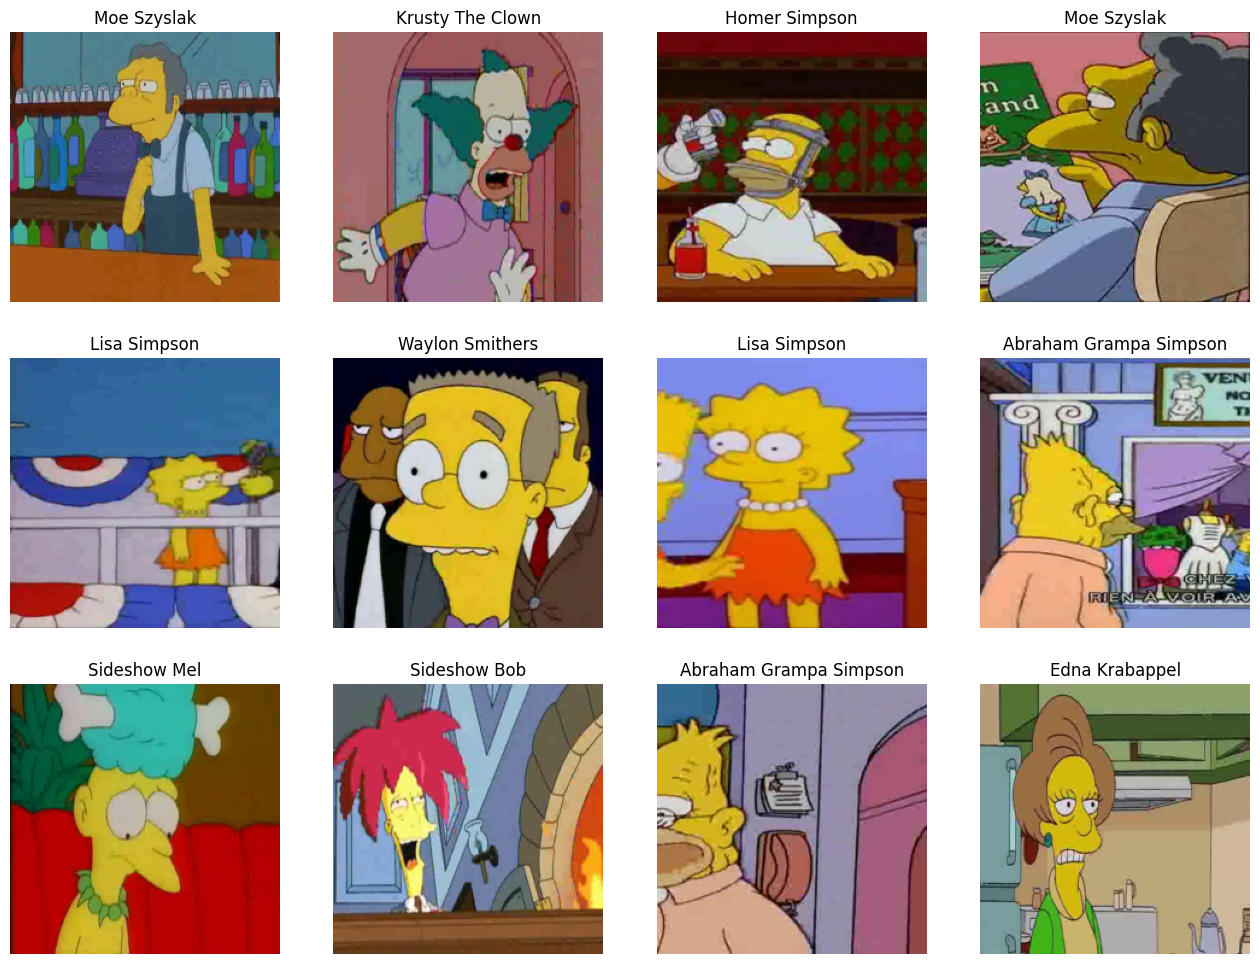

In [54]:
show_images(n_rows = 3, n_cols = 4, dataset = val_dataset)

## Шаг 3. Построение нейросети

Запустить данную сеть будет вашим мини-заданием на первую неделю, чтобы было проще участвовать в соревновании.

Данная архитектура будет очень простой и нужна для того, чтобы установить базовое понимание и получить простенький сабмит на Kaggle.

О том, как работают свёртки подробней можно прочитать в документации Pytorch на функцию `Conv2d`:

https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html

Калькулятор свёрток:

https://madebyollin.github.io/convnet-calculator/

#### Модель

In [55]:
class SimpleCnn(nn.Module):
    """
    Очень простая сверточная нейронная сеть для классификации изображений.

    Эта сеть состоит из пяти сверточных слоев, каждый из которых
    включает в себя операцию свертки, функцию активации ReLU и операцию
    пулинга (max-pooling). На выходе используется полносвязный слой
    для классификации на заданное количество классов.

    Параметры:
    ----------
    n_classes : int
        Количество классов для классификации.

    Примечание:
    ----------
    Входные изображения должны иметь размерность (3, H, W), где
    3 - слои rgb для цветной картинки, а H и W - высота и ширина изображения,
    соответственно. Размер выходного тензора будет равен (n_classes).

    Методы:
    -------
    forward(x):
        Пропускает входные данные через сеть и возвращает логиты для
        каждого класса.
    """

    def __init__(self, n_classes):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=8, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv2 = nn.Sequential(
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv3 = nn.Sequential(
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv4 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )
        self.conv5 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=96, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.out = nn.Linear(96 * 5 * 5, n_classes)


    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        x = x.view(x.size(0), -1)
        logits = self.out(x)
        return logits

*Описание слоев*:

1. размерность входа: $3\times 224 \times 224$
2. размерность после 1-го слоя (Conv2d + ReLU + MaxPool2d):  $8 \times 111 \times 111$
3. после 2-го слоя: $16 \times 54 \times 54$
4. после 3-го слоя: $32 \times 26 \times 26$
5. после 4-го слоя: $64 \times 12 \times 12$
6. после 5-го слоя: $96 \times 5 \times 5$
7. после полносвязного слоя (выход модели): количество классов

In [56]:
model_simple_cnn = SimpleCnn(n_classes = len(np.unique(train_val_labels)))
model_simple_cnn.to(DEVICE)
torchsummary.summary(model_simple_cnn, (3, 224, 224))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1          [-1, 8, 222, 222]             224
              ReLU-2          [-1, 8, 222, 222]               0
         MaxPool2d-3          [-1, 8, 111, 111]               0
            Conv2d-4         [-1, 16, 109, 109]           1,168
              ReLU-5         [-1, 16, 109, 109]               0
         MaxPool2d-6           [-1, 16, 54, 54]               0
            Conv2d-7           [-1, 32, 52, 52]           4,640
              ReLU-8           [-1, 32, 52, 52]               0
         MaxPool2d-9           [-1, 32, 26, 26]               0
           Conv2d-10           [-1, 64, 24, 24]          18,496
             ReLU-11           [-1, 64, 24, 24]               0
        MaxPool2d-12           [-1, 64, 12, 12]               0
           Conv2d-13           [-1, 96, 10, 10]          55,392
             ReLU-14           [-1, 96,

## Шаг 4. Функции для работы с моделью

#### Задание - напишите функции для работы с моделью

Обратите внимание, что метрика, которую необходимо оптимизировать в конкурсе -- `f1-score`.

Ниже приводится код для вычисления целевой метрики.

In [57]:
from sklearn.metrics import f1_score

# Многоклассовая задача (42 класса), поэтому обязателен average != 'binary'.
# 'micro' — глобальная точность/полнота по всем классам; 'macro' — среднее по классам.
def f1_metric(y_true, y_pred):
    # y_true/y_pred приходят как torch-тензоры на CPU -> переводим в numpy для sklearn
    y_true_np = y_true.cpu().numpy() if hasattr(y_true, 'numpy') else y_true
    y_pred_np = y_pred.cpu().numpy() if hasattr(y_pred, 'numpy') else y_pred
    return f1_score(y_true_np, y_pred_np, average='micro')

# пример расчета: f1 = f1_score(actual_labels, y_predicted, average='micro')

В этом задании может быть полезным сделать, чтобы функция валидации и, возможно, функция обучения на одной эпохе возвращали векторы/тензоры:
- предсказанного наиболее вероятного класса
- и фактических меток класса для каждого объекта.

Сама метрика f1, при этом, будет вычисляться не внутри функции, а вне ее, сопоставляя прогнозные и фактические значения, полученные из вывода функции.

Это поможет проанализировать, при предсказании каких классов модель ошибается чаще. Также такой подход может использоваться для обнаружения изображений, которые модель классифицирует неверно.

Для ускорения вычислений рекомендуется при работе с моделью проводить тензорные вычисления на GPU. Обращаем внимание, для этого необходимо, чтобы и данные, и модель находились на одном устройстве.

Ниже представлен код из предыдущего домашнего задания, который демонстрировал логику циклов обучения и валидации. Ниже в этот код добавлены строки комментарии, показывающие как переносить модель и данные на устройство.


```python
model.to(DEVICE)  # <- переносим модель на устройство DEVICE

for epoch in range(max_epochs):  
    # режим train
    model.train()  
    for x_batch, y_batch in train_dataloader:
        x_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        y_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        
        optimizer.zero_grad()
        outp = model(x_batch)
        loss = criterion(outp, y_batch)
        loss.backward()  
        optimizer.step()
        
        count_metrics(outp, y_batch)  # <-здесь, скорее всего, потребуется перенести данные на cpu, например с помощью метода cpu: metrics.cpu()
     
     # режим test/eval
     model.eval()  
     for x_batch, y_batch in val_dataloader:
        x_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        y_batch.to(DEVICE)  # <- переносим тензоры данных на устройство DEVICE
        
        with torch.no_grad():
            outp = model(x_batch)
            count_metrics(outp, y_batch) # <-здесь, скорее всего, потребуется перенести данные на cpu       
```

Напишите функции:
- для обучения модели на одной эпохе
- для валидации модели на одной эпохе
- для реализации полного цикла обучения

За основу можно взять функции, которые вы написали в предыдущем домашнем задании.

In [58]:
def count_metrics(outp, y_batch, preds, labels):
    # Без .cpu() внутри цикла: держим предсказания и метки на устройстве модели,
    # чтобы не делать дорогую пересылку GPU->CPU на каждом батче.
    # Перенос на CPU выполняется один раз в конце эпохи.
    preds.append(outp.argmax(-1).detach())
    labels.append(y_batch.detach())

In [59]:
def train_epoch(model, optimizer, criterion, train_loader, device, count_metrics):
    """
    Функция для обучения модели на одной эпохе.

    Параметры:
    ----------
    model : nn.Module
        Модель для обучения.
    optimizer : torch.optim.Optimizer
        Оптимизатор для обновления весов модели.
    criterion : torch.nn.modules.loss._Loss
        Функция потерь для вычисления ошибки.
    data_loader : torch.utils.data.DataLoader
        Загрузчик данных для обучения.
    device : torch.device
        Устройство (CPU или GPU) для выполнения вычислений.
    """
    model.to(device)
    model.train()

    preds = []
    labels = []
    losses = []
    for x_batch, y_batch in tqdm(train_loader):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        logits = model(x_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()

        count_metrics(logits, y_batch, preds, labels)
        losses.append(loss.item())
        
    y_pred = torch.cat(preds).cpu()
    y_true = torch.cat(labels).cpu()
    mean_loss = float(np.mean(losses))
    return y_pred, y_true, mean_loss

In [60]:
# YOUR CODE
test_tensor = torch.tensor(((2.0, 2.0), (2.0, 2.0)), requires_grad=True)
squared_tensor = torch.sum(test_tensor ** 2)
squared_tensor.backward()
print(test_tensor.grad)

tensor([[4., 4.],
        [4., 4.]])


In [61]:
def val_model(model, val_loader, criterion, device, count_metrics):
    """
    Функция для валидации модели на валидационном наборе данных.

    Параметры:
    ----------
    model : nn.Module
        Модель для валидации.
    criterion : torch.nn.modules.loss._Loss
        Функция потерь для вычисления ошибки.
    val_loader : torch.utils.data.DataLoader
        Загрузчик данных для валидации.
    device : torch.device
        Устройство (CPU или GPU) для выполнения вычислений.
    """
    model.to(device)
    model.eval()

    preds = []
    labels = []
    losses = []
    for x_batch, y_batch in tqdm(val_loader):
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        with torch.no_grad():
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            losses.append(loss.item())
            count_metrics(logits, y_batch, preds, labels)

    y_pred = torch.cat(preds).cpu()
    y_true = torch.cat(labels).cpu()
    mean_loss = float(np.mean(losses))
    return y_pred, y_true, mean_loss

In [62]:
def train_model(model, loaders, criterion, optimizer, metric, n_epochs=5):
    """
    Функция для обучения модели.

    Параметры:
    ----------
    model : nn.Module
        Модель, которую нужно обучить.
    loaders : dict
        Словарь с DataLoader'ами для обучения и валидации.
        Должен содержать ключи 'train' и 'val'.
    criterion : torch.nn.modules.loss._Loss
        Функция потерь.
    optimizer : torch.optim.Optimizer
        Оптимизатор для обновления весов модели.
    metric : callable
        Метрика для оценки производительности модели.
    n_epochs : int, optional
        Количество эпох для обучения (по умолчанию 5).

    Возвращает:
    ---------
    model : nn.Module
        Обученная модель.
    history : dict
        История обучения, содержащая потери и метрику для каждой эпохи.
    """

    history = {'train_loss': [], 'train_metric': [], 'val_loss': [], 'val_metric': []}
    for epoch in range(n_epochs):
        print(f'Epoch {epoch + 1}/{n_epochs}')
        print('-' * 10)

        # Обучение на тренировочном наборе
        y_pred, y_true, train_loss = train_epoch(model, optimizer, criterion, loaders['train'], DEVICE, count_metrics)
        train_metric = metric(y_true, y_pred)
        history['train_loss'].append(train_loss)
        history['train_metric'].append(train_metric)

        # Валидация на валидационном наборе
        y_pred, y_true, val_loss = val_model(model, loaders['val'], criterion, DEVICE, count_metrics)
        val_metric = metric(y_true, y_pred)
        history['val_loss'].append(val_loss)
        history['val_metric'].append(val_metric)

        print(f'Train Loss: {train_loss:.4f} Train Metric: {train_metric:.4f}')
        print(f'Val Loss: {val_loss:.4f} Val Metric: {val_metric:.4f}')

    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.legend()
    plt.show()

    plt.plot(history['train_metric'], label='Train Metric')
    plt.plot(history['val_metric'], label='Val Metric')
    plt.legend()
    plt.show()

## Шаг 5. Применение модели к данным

#### Применение модели к данным

In [63]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model_simple_cnn.parameters(), lr = 1e-3)

Запустите обучение сети

### Обучение cnn модели

Обучаем SimpleCNN...
Epoch 1/5
----------


100%|██████████| 82/82 [00:39<00:00,  2.08it/s]


Train Loss: 3.2207 Train Metric: 0.1644
Val Loss: 3.0343 Val Metric: 0.1970
Epoch 2/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.04it/s]


Train Loss: 2.1304 Train Metric: 0.4435
Val Loss: 2.2522 Val Metric: 0.3831
Epoch 3/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.01it/s]


Train Loss: 1.5603 Train Metric: 0.5990
Val Loss: 2.0831 Val Metric: 0.4618
Epoch 4/5
----------


100%|██████████| 82/82 [00:39<00:00,  2.10it/s]


Train Loss: 1.2805 Train Metric: 0.6572
Val Loss: 1.7266 Val Metric: 0.5449
Epoch 5/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.00it/s]

Train Loss: 1.0736 Train Metric: 0.7128
Val Loss: 1.5215 Val Metric: 0.5858


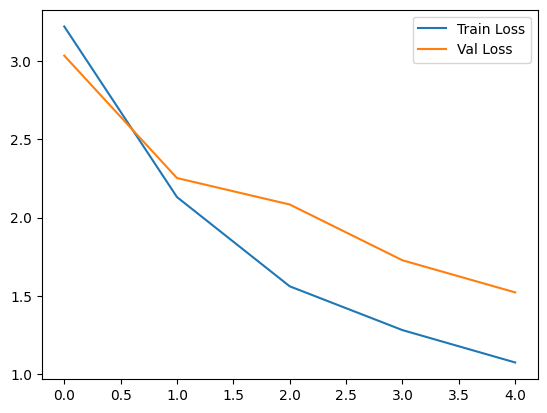

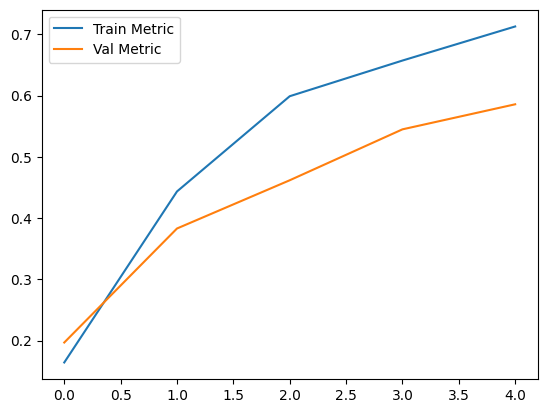

RuntimeError: Parent directory /content/drive/MyDrive/dls/dls_part_1/weights/hw_5 does not exist.

In [ ]:
simple_cnn_weights_path = weights_folder / 'simple_cnn_weights.pth'
FORCE_RETRAIN_SIMPLE_CNN = False

if simple_cnn_weights_path.exists() and not FORCE_RETRAIN_SIMPLE_CNN:
    print(f"Загружаем сохраненные веса {simple_cnn_weights_path}...")
    model_simple_cnn.load_state_dict(torch.load(simple_cnn_weights_path, map_location=DEVICE))
else:
    print("Обучаем SimpleCNN...")
    train_model(model_simple_cnn, loaders, criterion, optimizer, f1_metric, n_epochs=5)
    torch.save(model_simple_cnn.state_dict(), simple_cnn_weights_path)
    print(f"Веса SimpleCNN сохранены в {simple_cnn_weights_path}")

In [66]:
simple_cnn_weights_path = weights_folder / 'simple_cnn_weights.pth'
FORCE_RETRAIN_SIMPLE_CNN = False



torch.save(model_simple_cnn.state_dict(), simple_cnn_weights_path)
print(f"Веса SimpleCNN сохранены в {simple_cnn_weights_path}")


Веса SimpleCNN сохранены в /content/drive/MyDrive/dls/dls_part_1/weights/hw_5/simple_cnn_weights.pth


### ResNet18

1. обучение fc слоев
2. дообучение всей сети

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


=== Шаг 1: Обучение классификатора ResNet18 ===
Epoch 1/3
----------


100%|██████████| 82/82 [00:41<00:00,  1.97it/s]


Train Loss: 2.5782 Train Metric: 0.4174
Val Loss: 2.2799 Val Metric: 0.4536
Epoch 2/3
----------


100%|██████████| 82/82 [00:40<00:00,  2.04it/s]


Train Loss: 1.5349 Train Metric: 0.6729
Val Loss: 1.9113 Val Metric: 0.5132
Epoch 3/3
----------


100%|██████████| 82/82 [00:41<00:00,  1.96it/s]

Train Loss: 1.2115 Train Metric: 0.7235
Val Loss: 1.6664 Val Metric: 0.5741


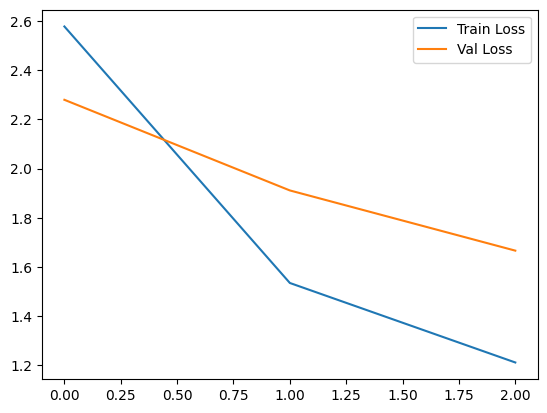

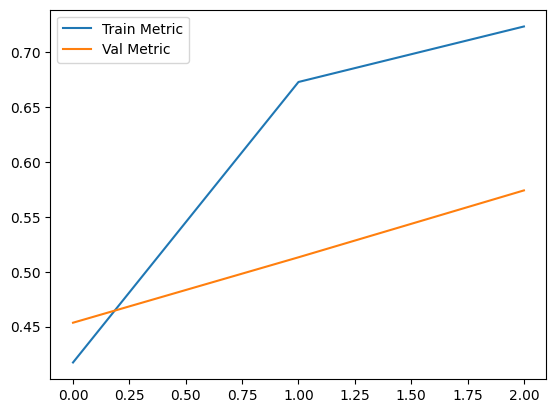

=== Шаг 2: Дообучение всей сети ResNet18 ===
Epoch 1/5
----------


100%|██████████| 82/82 [00:41<00:00,  1.97it/s]


Train Loss: 0.2849 Train Metric: 0.9360
Val Loss: 0.3418 Val Metric: 0.9102
Epoch 2/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.01it/s]


Train Loss: 0.0866 Train Metric: 0.9822
Val Loss: 0.2533 Val Metric: 0.9316
Epoch 3/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.03it/s]


Train Loss: 0.0654 Train Metric: 0.9853
Val Loss: 0.2352 Val Metric: 0.9375
Epoch 4/5
----------


100%|██████████| 82/82 [00:38<00:00,  2.11it/s]


Train Loss: 0.0398 Train Metric: 0.9917
Val Loss: 0.2020 Val Metric: 0.9488
Epoch 5/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.04it/s]


Train Loss: 0.0367 Train Metric: 0.9929
Val Loss: 0.2407 Val Metric: 0.9402


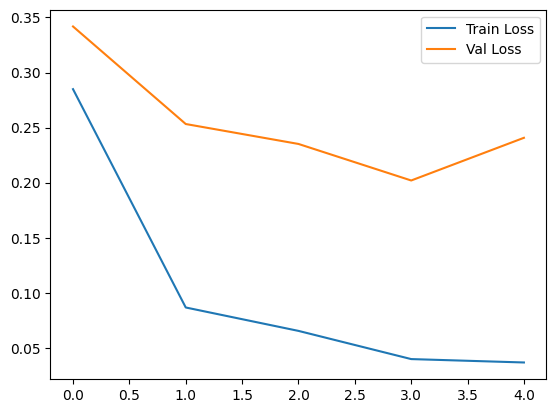

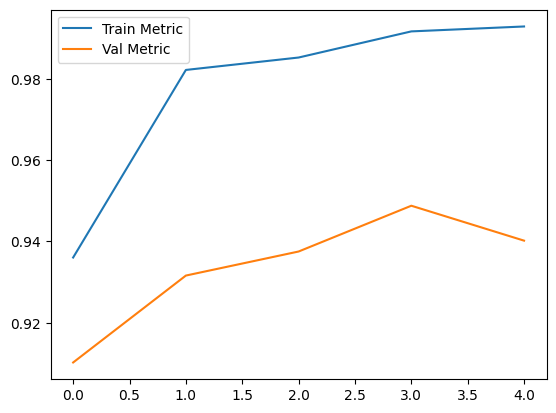

Веса ResNet18 сохранены в /content/drive/MyDrive/dls/dls_part_1/weights/hw_5/resnet18_baseline_weights.pth


In [67]:
from pathlib import Path
from torchvision import models
from torchvision.models import ResNet18_Weights

# Используем ResNet18 с предобученными весами ImageNet
resnet18 = models.resnet18(weights=ResNet18_Weights.DEFAULT)
resnet18.fc = nn.Linear(resnet18.fc.in_features, len(label_encoder.classes_))
resnet18 = resnet18.to(DEVICE)

resnet18_weights_path = weights_folder / 'resnet18_baseline_weights.pth'
FORCE_RETRAIN_RESNET18 = False

if resnet18_weights_path.exists() and not FORCE_RETRAIN_RESNET18:
    print(f"Загружаем сохраненные веса {resnet18_weights_path}...")
    resnet18.load_state_dict(torch.load(resnet18_weights_path, map_location=DEVICE))
else:
    # Шаг 1: замораживаем backbone, обучаем только классификатор
    for param in resnet18.parameters():
        param.requires_grad = False
    for param in resnet18.fc.parameters():
        param.requires_grad = True

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, resnet18.parameters()),
        lr=1e-3
    )

    print("=== Шаг 1: Обучение классификатора ResNet18 ===")
    train_model(resnet18, loaders, criterion, optimizer, f1_metric, n_epochs=3)

    # Шаг 2: дообучаем всю сеть на маленьком learning rate
    for param in resnet18.parameters():
        param.requires_grad = True

    optimizer = torch.optim.AdamW(resnet18.parameters(), lr=1e-4)

    print("=== Шаг 2: Дообучение всей сети ResNet18 ===")
    train_model(resnet18, loaders, criterion, optimizer, f1_metric, n_epochs=5)

    torch.save(resnet18.state_dict(), resnet18_weights_path)
    print(f"Веса ResNet18 сохранены в {resnet18_weights_path}")


(опционально) Постройте график динамики метрик модели по ходу обучения

### Ну и что теперь со всем этим делать?

![alt text](https://www.indiewire.com/wp-content/uploads/2014/08/the-simpsons.jpg)

Сделаем классную визуализацию,  чтобы посмотреть насколько сеть уверена в своих ответах.

In [68]:
import matplotlib.patches as patches
from matplotlib.font_manager import FontProperties

@torch.no_grad()
def show_images2(n_rows, n_cols, dataset, model):
  # функция выводит изображения в n_rows рядов и n_cols столбцов
  fig, axs = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(n_cols * 4, n_rows * 4), \
                        sharey=True, sharex=True)

  for fig_x in axs.flatten(): # цикл повторяется (n_rows * n_cols) раз
    random_characters = int(np.random.uniform(0, len(dataset))) # берем случайное число в диапазоне [0; len(dataset))
    im_val, label = dataset[random_characters] # выводим изображение (тензорная форма)
    img_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([label])[0].split('_')))  # числовую метку класса преобразуем в текстовую и немного отформатируем
    imshow(im_val.data.cpu(), title=img_label, plt_ax=fig_x) # отобразим изображение и метку класса с помощью написанной ранее функции imshow()

    # ниже представлен код для добавления на изображение подписи с вероятностью класса
    actual_text = "Actual : {}".format(img_label)


    font0 = FontProperties()
    font = font0.copy()

    # наша модель возвращает логиты, поэтому для получения вероятностей классов не забываем применить softmax:
    prob_pred = nn.functional.softmax(model(im_val.unsqueeze(0).to(DEVICE)), dim = -1).cpu().numpy()

    predicted_proba = np.max(prob_pred)*100 # берем максимальную вероятность класса
    y_pred = np.argmax(prob_pred) # берем числовую метку класса, для которого вероятность максимальна

    predicted_label = " ".join(map(lambda x: x.capitalize(), \
                             label_encoder.inverse_transform([y_pred])[0].split('_')))
    predicted_text = "{}:\n {:.1f}%".format(predicted_label, predicted_proba)

    fig_x.add_patch(patches.Rectangle((0, 190), 7*len(predicted_label), 25,color='white'))
    fig_x.text(2, 195, predicted_text , horizontalalignment='left', fontproperties=font,
                    verticalalignment='top',fontsize=8, color='black',fontweight='bold')
    fig_x.set_axis_off()

  return None

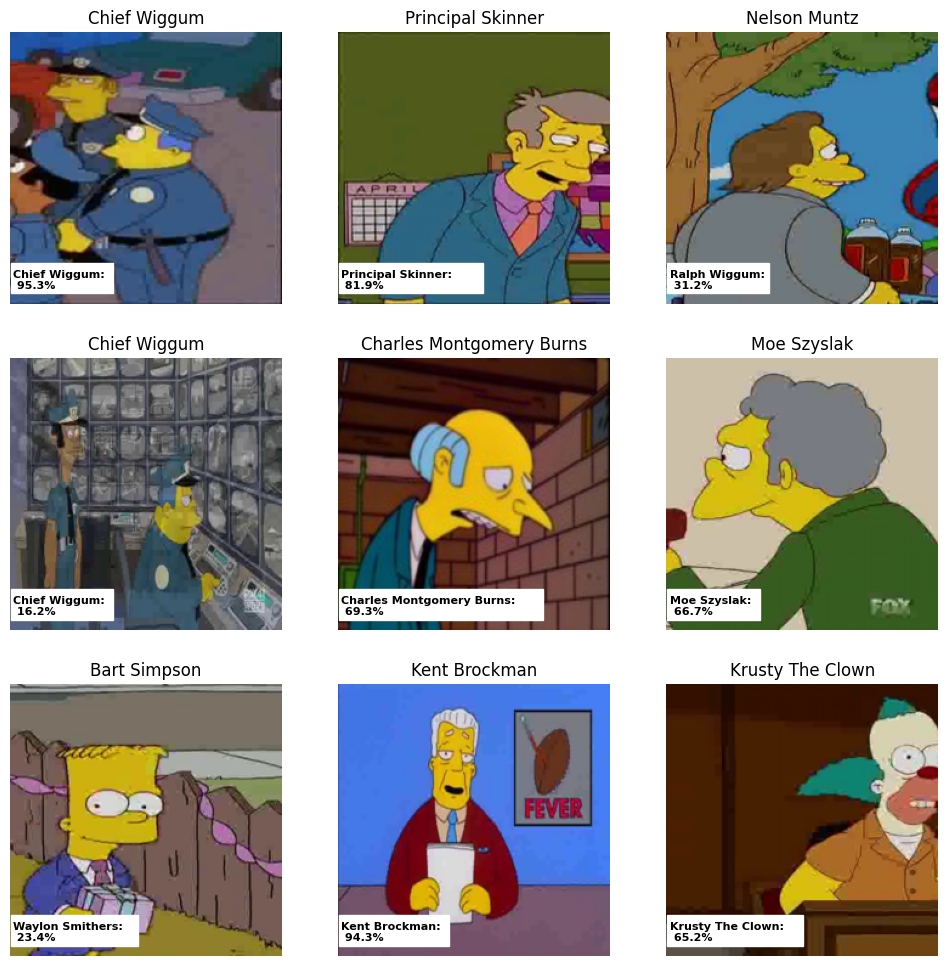

In [69]:
show_images2(n_rows = 3, n_cols = 3, dataset = val_dataset, model = model_simple_cnn)

## Шаг 6. Submit на Kaggle

![alt text](https://i.redd.it/nuaphfioz0211.jpg)

Создадим loader для тестовых данных

In [70]:
test_dataset = SimpsonsDataset(test_files, label_encoder = label_encoder, mode="test")
test_loader = DataLoader(test_dataset, shuffle=False, batch_size=64)

Воспользуемся функцией predict, которая возвращает предсказанные числовые метки для всех объектов в лоадере.

In [71]:
def predict(model, loader):
    model.eval()
    all_predictions = torch.tensor([]).to(DEVICE).int()
    print("Test mode...")
    for inputs in tqdm(loader):
        inputs = inputs.to(DEVICE)

        with torch.no_grad():
            outputs = model(inputs)

            predictions = outputs.argmax(-1).int()
            all_predictions = torch.cat((all_predictions, predictions), 0)
    return all_predictions.cpu()

Получем предсказание меток классов для тестовых данных:

In [72]:
# predicted_numeric_labels = predict(model_simple_cnn, test_loader)
predicted_numeric_labels = predict(resnet18, test_loader)

Test mode...


100%|██████████| 16/16 [00:03<00:00,  4.57it/s]


и преобразуем их в текстовые метки:

In [73]:
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)

Загрузим пример файла для загрузки на Kaggle (проверьте путь, по которому у вас лежит файл sample_submission.csv и при необходимости скорректируйте путь в коде ниже):

In [74]:
import pandas as pd
sample_submission = pd.read_csv("/content/sample_submission.csv")
sample_submission.head(10)

,Id,Expected
0,img0.jpg,bart_simpson
1,img1.jpg,bart_simpson
2,img2.jpg,bart_simpson
3,img3.jpg,bart_simpson
4,img4.jpg,bart_simpson
5,img5.jpg,bart_simpson
6,img6.jpg,bart_simpson
7,img7.jpg,bart_simpson
8,img8.jpg,bart_simpson
9,img9.jpg,bart_simpson


In [75]:
my_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})
my_submission.head(10)

,Id,Expected
0,img0.jpg,nelson_muntz
1,img1.jpg,bart_simpson
2,img10.jpg,ned_flanders
3,img100.jpg,chief_wiggum
4,img101.jpg,apu_nahasapeemapetilon
5,img102.jpg,kent_brockman
6,img103.jpg,edna_krabappel
7,img104.jpg,chief_wiggum
8,img105.jpg,lisa_simpson
9,img106.jpg,kent_brockman


In [76]:
# TODO : сделайте сабмит (это важно, если Вы не справляетесь, но дошли до этой ячейки, то сообщите в чат и Вам помогут)

In [77]:
# my_submission.to_csv('resnet18_cnn_baseline.csv', index=False)

## Приключение?

А теперь самое интересное, мы сделали простенькую сверточную сеть и смогли отправить сабмит, но получившийся score нас явно не устраивает. Надо с этим что-то сделать.

Вам предлагается творческая и исследовательская свобода в том, как вы будете улучшать score модели. Вот некоторые направления, которые вы, возможно, захотите попробовать:
1. Работа с датасетом:
* Попробуйте увеличить разнообразие обучающей выборки при помощи аугментации ([ссылка 1](https://habr.com/ru/companies/smartengines/articles/264677/), [ссылка 2](https://www.geeksforgeeks.org/python-data-augmentation/));
* Используя результаты функции eval_one_epoch, вы можете посмотреть, как метрика f1-score внутри класса связана с размером самого класса в обучающей выборке. Скорее всего, вы заметите прямую зависимость. Решением может быть увеличение размеров слабо представленных классов. Сделать это можно, вручную добавив этот функционал в SimpsonsDataset или воспользовавшись инструментом WeightedRandomSampler.

* Также вы можете изучить, какие изображения модель классифицирует неверно. Можно просто посмотреть неверно классифицированные изображения в валидационном датасете. Можно попробовать более фундаментальный подход - создать dataloader из всех изображений обучающей и валидационной выборки в SimpsonsDataset c режимом 'val', прогнать данные через обученную модель simple_cnn. Более того, можно обучить несколько моделей с разной архитектурой, и прогнать объединенный датасет через все эти модели - и выделить те изображения, в классификации которых ошиблись несколько моделей.

* Это поможет понять, как качество и чистота исходных данных влияет на результаты обучения модели. Если вы обнаружите ошибки в simpsons_dataset и решите их исправить или удалить некоторые изображения из обучающей выборки - сделайте это в ноутбуке, чтобы при проверке можно было повторить результаты работы вашего кода.  

2. Работа с архитектурой сети:
* учим дольше и изменяем (подбираем) гиперпараметры: learning rate, batch size, нормализация картинки и вот это всё;
* добавление/удаление свёрточных и полносвязных слоёв;
* А еще есть где пулинги и батч-норм!

3. Применение техник, описанных в предыдущих пунктах, позволяет добиться довольно высоких результатов. Но вы можете попробовать файнтютинг и трансферлёнинг:
* ну разве это deep learning? Вот ResNet и Inception, которые можно зафайнтьюнить под наши данные, вот это я понимаю (можно и обучить в колабе, а можно и [готовые](https://github.com/Cadene/pretrained-models.pytorch) скачать).

4. Улучшение оптимизации:
* ну разве Адам наше все? [adamW](https://www.fast.ai/2018/07/02/adam-weight-decay/) для практика, [статейка для любителей](https://openreview.net/pdf?id=ryQu7f-RZ) (очень хороший анализ), [наши ](https://github.com/MichaelKonobeev/adashift/) эксперименты для заинтересованных.

5. Наконец, возможно, стоит подумать об ансамблях


Надеюсь, что у Вас получится!

---
## Дополнительное исследование 1: Зависимость F1-score от размера класса

1. Считаем F1-score для каждого отдельного класса на валидационной выборке;
2. Сопоставляем его с количеством обучающих примеров данного класса;
3. Вычисляем коэффициенты корреляции Пирсона и Спирмена;
4. Визуализируем эту зависимость.

=== Анализ зависимости F1-score от размера класса ===
Корреляция Пирсона:  r = 0.3547 (p-value = 2.1183e-02)
Корреляция Спирмена: rho = 0.6246 (p-value = 9.8367e-06)

Топ-5 самых малочисленных классов:


,class_id,class_name,train_samples,val_samples,f1_score
0,19,lionel_hutz,2,1,0.000000
1,10,disco_stu,6,2,0.000000
2,40,troy_mcclure,6,2,1.000000
3,26,miss_hoover,13,4,0.400000
4,13,gil,20,7,0.833333



Топ-5 самых многочисленных классов:


,class_id,class_name,train_samples,val_samples,f1_score
37,4,bart_simpson,1006,336,0.948995
38,20,lisa_simpson,1015,339,0.963181
39,27,moe_szyslak,1089,363,0.939655
40,28,ned_flanders,1090,364,0.948509
41,15,homer_simpson,1684,562,0.936323


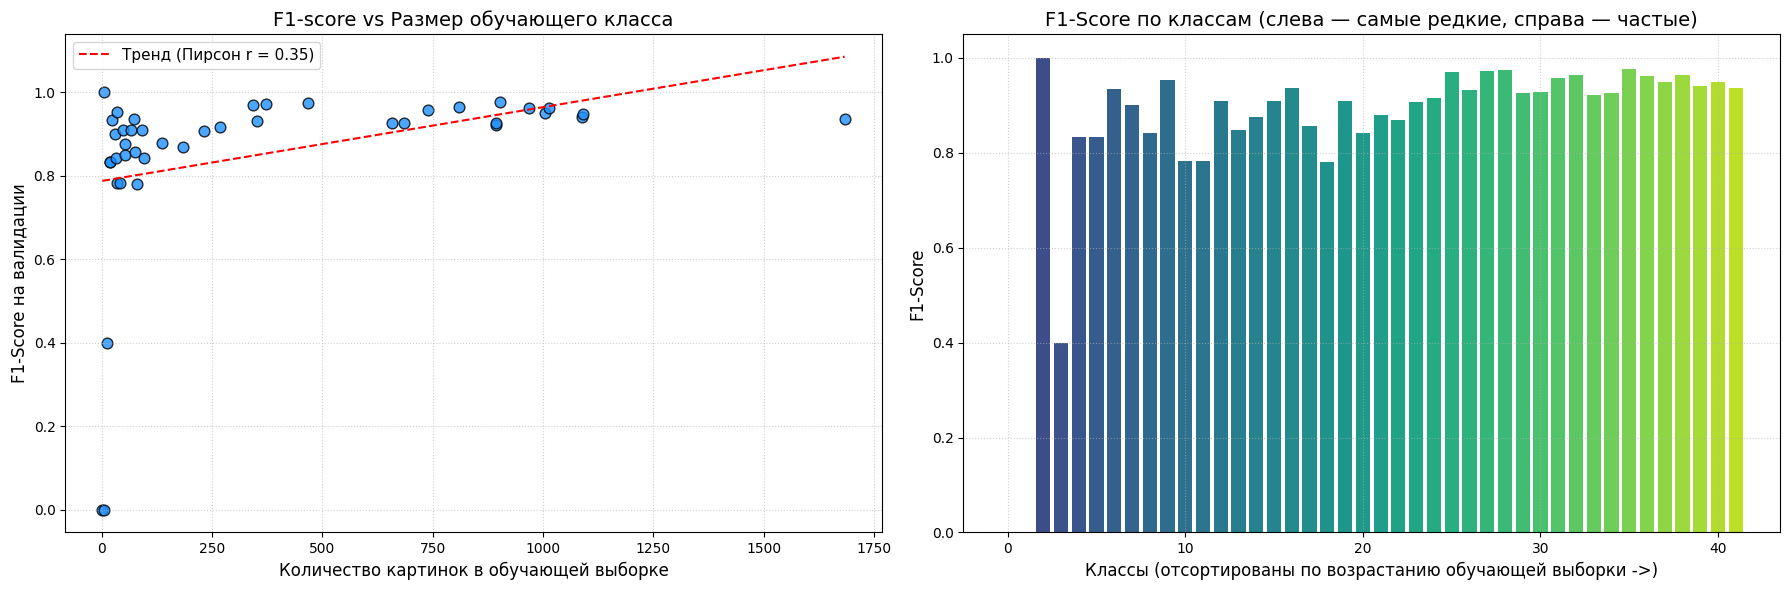

In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import f1_score, classification_report

# 1. Получаем предсказания модели на валидационной выборке
eval_model = resnet18
eval_model.eval()

val_preds = []
val_targets = []

with torch.no_grad():
    for x_batch, y_batch in val_loader:
        x_batch = x_batch.to(DEVICE)
        logits = eval_model(x_batch)
        preds = logits.argmax(-1).cpu()
        val_preds.extend(preds.numpy())
        val_targets.extend(y_batch.numpy())

val_preds = np.array(val_preds)
val_targets = np.array(val_targets)

# 2. Считаем per-class F1-score
n_classes = len(label_encoder.classes_)
per_class_f1 = f1_score(val_targets, val_preds, average=None, labels=range(n_classes), zero_division=0)

# 3. Считаем число картинок каждого класса в обучающей выборке
train_labels = [label_encoder.transform([p.parent.name])[0] for p in train_dataset.files]
train_class_counts = np.bincount(train_labels, minlength=n_classes)
val_class_counts = np.bincount(val_targets, minlength=n_classes)

# 4. Формируем DataFrame со статистикой по всем классам
class_names = [label_encoder.inverse_transform([i])[0] for i in range(n_classes)]
df_class_f1 = pd.DataFrame({
    "class_id": range(n_classes),
    "class_name": class_names,
    "train_samples": train_class_counts,
    "val_samples": val_class_counts,
    "f1_score": per_class_f1
}).sort_values(by="train_samples", ascending=True).reset_index(drop=True)

# 5. Расчет корреляций
corr_pearson, p_pearson = pearsonr(df_class_f1["train_samples"], df_class_f1["f1_score"])
corr_spearman, p_spearman = spearmanr(df_class_f1["train_samples"], df_class_f1["f1_score"])

print("=== Анализ зависимости F1-score от размера класса ===")
print(f"Корреляция Пирсона:  r = {corr_pearson:.4f} (p-value = {p_pearson:.4e})")
print(f"Корреляция Спирмена: rho = {corr_spearman:.4f} (p-value = {p_spearman:.4e})")
print("\nТоп-5 самых малочисленных классов:")
display(df_class_f1.head(5))
print("\nТоп-5 самых многочисленных классов:")
display(df_class_f1.tail(5))

# 6. Визуализация
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# График 1: Scatter plot с линией тренда
axes[0].scatter(df_class_f1["train_samples"], df_class_f1["f1_score"], color="dodgerblue", edgecolors="black", s=60, alpha=0.8)
m, b = np.polyfit(df_class_f1["train_samples"], df_class_f1["f1_score"], 1)
axes[0].plot(df_class_f1["train_samples"], m * df_class_f1["train_samples"] + b, color="red", linestyle="--", label=f"Тренд (Пирсон r = {corr_pearson:.2f})")
axes[0].set_xlabel("Количество картинок в обучающей выборке", fontsize=12)
axes[0].set_ylabel("F1-Score на валидации", fontsize=12)
axes[0].set_title("F1-score vs Размер обучающего класса", fontsize=14)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(fontsize=11)

# График 2: Столбчатый график F1 по классам, отсортированным по размеру
bar_colors = plt.cm.viridis(np.linspace(0.2, 0.9, len(df_class_f1)))
axes[1].bar(range(len(df_class_f1)), df_class_f1["f1_score"], color=bar_colors)
axes[1].set_xlabel("Классы (отсортированы по возрастанию обучающей выборки ->)", fontsize=12)
axes[1].set_ylabel("F1-Score", fontsize=12)
axes[1].set_title("F1-Score по классам (слева — самые редкие, справа — частые)", fontsize=14)
axes[1].set_ylim(0, 1.05)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

---
## Дополнительное исследование 2: Фундаментальный анализ ошибок на полном датасете и несколькими моделями

### Идея:
1. Создаем единый `SimpsonsDataset` из всех размеченных изображений (`train_files + val_files`) в детерминированном режиме `mode="val"` (без случайных аугментаций, фиксированный resize и нормализация).
2. Прогоняем объединенный датасет через несколько моделей с разной архитектурой (`SimpleCNN` и дообученный `ResNet18`).
3. Находим изображения, на которых ошиблись несколько моделей одновременно.
4. Выводим проблемные изображения с предсказаниями и уверенностями каждой модели.

In [79]:
# 1. Формируем объединенный датасет из train и val файлов в режиме "val"
all_files = sorted(train_files + val_files)
all_dataset = SimpsonsDataset(all_files, label_encoder=label_encoder, mode="val")
all_loader = DataLoader(all_dataset, batch_size=batch_size, shuffle=False, num_workers=2, prefetch_factor=2, pin_memory=True)

print(f"Объединенный датасет: {len(all_dataset)} изображений ({len(train_files)} train + {len(val_files)} val)")

Объединенный датасет: 20933 изображений (15699 train + 5234 val)


In [80]:
def get_model_predictions_and_probs(model, loader, device=DEVICE):
    """
    Возвращает предсказанные классы, истинные метки и вероятности softmax для всех объектов в loader.
    """
    model.eval()
    all_preds = []
    all_targets = []
    all_probs = []
    
    with torch.no_grad():
        for x_batch, y_batch in tqdm(loader, desc="Inference"):
            x_batch = x_batch.to(device)
            logits = model(x_batch)
            probs = torch.softmax(logits, dim=-1).cpu()
            preds = logits.argmax(-1).cpu()
            
            all_preds.extend(preds.numpy())
            all_targets.extend(y_batch.numpy())
            all_probs.extend(probs.numpy())
            
    return np.array(all_preds), np.array(all_targets), np.array(all_probs)

# 2. Собираем словарь моделей для сравнительного анализа
models_to_analyze = {}
if "resnet18" in globals():
    models_to_analyze["ResNet18"] = resnet18
if "model_simple_cnn" in globals():
    models_to_analyze["SimpleCNN"] = model_simple_cnn

print(f"Модели для анализа ошибок: {list(models_to_analyze.keys())}")

# 3. Прогоняем объединенный датасет через каждую модель
predictions_dict = {}
probs_dict = {}
true_labels = None

for model_name, model_obj in models_to_analyze.items():
    print(f"\nПрогон через {model_name}...")
    preds, targets, probs = get_model_predictions_and_probs(model_obj, all_loader)
    predictions_dict[model_name] = preds
    probs_dict[model_name] = probs
    if true_labels is None:
        true_labels = targets

Модели для анализа ошибок: ['ResNet18', 'SimpleCNN']

Прогон через ResNet18...


Inference: 100%|██████████| 328/328 [02:38<00:00,  2.07it/s]



Прогон через SimpleCNN...


Inference: 100%|██████████| 328/328 [02:34<00:00,  2.13it/s]


In [81]:
# 4. Формируем единый DataFrame со всеми предсказаниями и анализом консенсуса ошибок
df_analysis = pd.DataFrame({
    "file_path": [str(p) for p in all_files],
    "filename": [p.name for p in all_files],
    "true_label_id": true_labels,
    "true_label": label_encoder.inverse_transform(true_labels),
})

error_columns = []
for model_name in models_to_analyze.keys():
    preds = predictions_dict[model_name]
    probs = probs_dict[model_name]
    pred_labels = label_encoder.inverse_transform(preds)
    confidences = np.max(probs, axis=1)
    is_error = (preds != true_labels)
    
    df_analysis[f"{model_name}_pred"] = pred_labels
    df_analysis[f"{model_name}_conf"] = confidences
    df_analysis[f"{model_name}_error"] = is_error
    error_columns.append(f"{model_name}_error")

# Считаем, сколько моделей ошиблись на каждом конкретном изображении
df_analysis["errors_count"] = df_analysis[error_columns].sum(axis=1)
df_analysis["is_consensus_error"] = df_analysis["errors_count"] == len(models_to_analyze)

# Вывод сводной статистики
print("=== Сводка качества моделей на полном датасете ===")
for model_name in models_to_analyze.keys():
    err_cnt = df_analysis[f"{model_name}_error"].sum()
    acc = 1.0 - (err_cnt / len(df_analysis))
    print(f"{model_name}: Точность = {acc * 100:.2f}% | Ошибок: {err_cnt} из {len(df_analysis)}")

consensus_errors_df = df_analysis[df_analysis["is_consensus_error"]]
print(f"\nКонсенсусных ошибок: {len(consensus_errors_df)}")

=== Сводка качества моделей на полном датасете ===
ResNet18: Точность = 96.17% | Ошибок: 801 из 20933
SimpleCNN: Точность = 61.26% | Ошибок: 8109 из 20933

Консенсусных ошибок: 634


/tmp/ipykernel_5502/2838073355.py:34: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128680 (\N{POLICE CARS REVOLVING LIGHT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


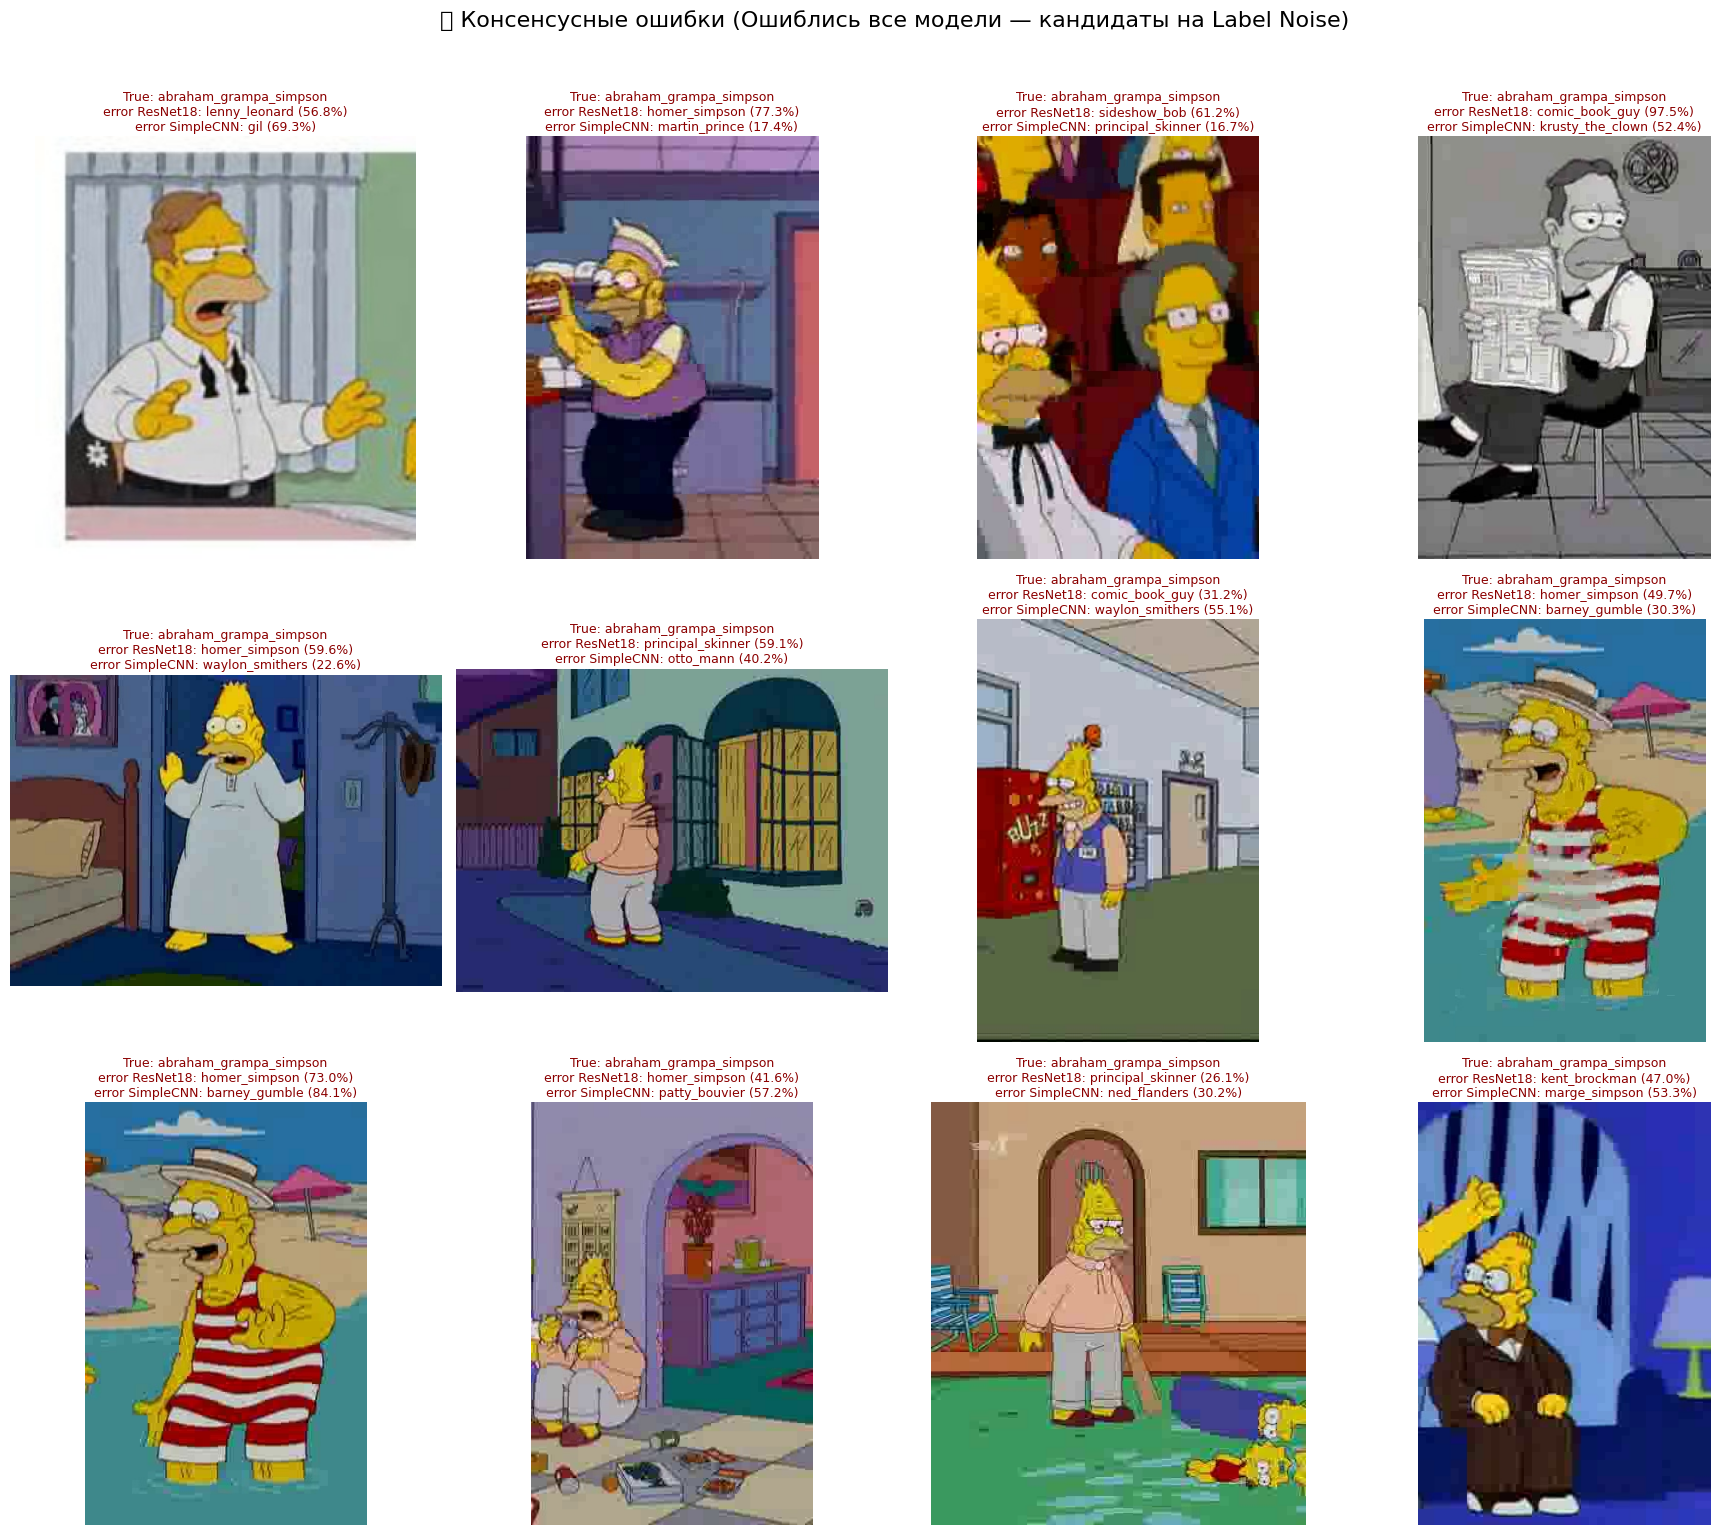

In [82]:
# 5. Функция визуализации консенсусных и сложных ошибок
def plot_misclassified_images(df_errors, max_images=12, title="Консенсусные ошибки моделей"):
    if len(df_errors) == 0:
        print("Ошибок не найдено!")
        return
    
    n_to_show = min(max_images, len(df_errors))
    n_cols = 4
    n_rows = int(np.ceil(n_to_show / n_cols))
    
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(18, 5 * n_rows))
    axs = axs.flatten() if n_to_show > 1 else [axs]
    
    for i in range(len(axs)):
        if i < n_to_show:
            row = df_errors.iloc[i]
            img = Image.open(row["file_path"])
            axs[i].imshow(img)
            
            # Формируем подпись с предсказаниями моделей и их уверенностью
            title_lines = [f"True: {row['true_label']}"]
            for m_name in models_to_analyze.keys():
                pred = row[f"{m_name}_pred"]
                conf = row[f"{m_name}_conf"] * 100
                err = "error" if row[f"{m_name}_error"] else "good"
                title_lines.append(f"{err} {m_name}: {pred} ({conf:.1f}%)")
            
            axs[i].set_title("\n".join(title_lines), fontsize=9, color="darkred", pad=4)
            axs[i].axis("off")
        else:
            axs[i].axis("off")
            
    plt.suptitle(title, fontsize=16, y=1.02)
    plt.tight_layout()
    plt.show()

# Отображаем консенсусные ошибки (если они есть) или топ ошибок ResNet18
if len(consensus_errors_df) > 0:
    plot_misclassified_images(consensus_errors_df, max_images=12, title="🚨 Консенсусные ошибки (Ошиблись все модели — кандидаты на Label Noise)")
else:
    resnet_errors = df_analysis[df_analysis["ResNet18_error"]]
    plot_misclassified_images(resnet_errors, max_images=12, title="Ошибки ResNet18 на полном датасете")

In [83]:
# 6. Таблица кандидатов на удаление/исправление разметки (Label Noise)
# Отсортируем консенсусные ошибки по максимальной уверенности моделей в своем (неверном) ответе:
first_model = list(models_to_analyze.keys())[0]
suspicious_samples = consensus_errors_df.sort_values(by=f"{first_model}_conf", ascending=False)

print("Топ-10 самых подозрительных изображений (высокая уверенность модели при несовпадении с меткой):")
display(suspicious_samples[["filename", "true_label"] + [f"{m}_pred" for m in models_to_analyze] + [f"{m}_conf" for m in models_to_analyze]].head(10))

Топ-10 самых подозрительных изображений (высокая уверенность модели при несовпадении с меткой):


,filename,true_label,ResNet18_pred,SimpleCNN_pred,ResNet18_conf,SimpleCNN_conf
1634,pic_0056.jpg,barney_gumble,bart_simpson,bart_simpson,0.999846,0.817982
13013,pic_0809.jpg,marge_simpson,lisa_simpson,lisa_simpson,0.999688,0.499709
7188,pic_0729.jpg,homer_simpson,abraham_grampa_simpson,martin_prince,0.999166,0.945100
2396,pic_0712.jpg,bart_simpson,marge_simpson,marge_simpson,0.998172,0.999745
19504,pic_0034.jpg,professor_john_frink,principal_skinner,charles_montgomery_burns,0.997110,0.400607
7005,pic_0546.jpg,homer_simpson,nelson_muntz,nelson_muntz,0.996846,0.298712
6152,pic_0327.jpg,edna_krabappel,ned_flanders,marge_simpson,0.996718,0.239482
7741,pic_1282.jpg,homer_simpson,marge_simpson,milhouse_van_houten,0.994181,0.676728
11356,pic_0634.jpg,lisa_simpson,marge_simpson,marge_simpson,0.993403,0.984537
17290,pic_0930.jpg,ned_flanders,edna_krabappel,edna_krabappel,0.991830,0.413610


---
## Очистка датасета от шумной разметки

**Стратегия отбора кандидатов на удаление**:
   - Выбираем консенсусные ошибки;
   - Фильтруем по высокой уверенности предсказания моделей ($> 85-90\%$), так как высокая уверенность сети при расхождении с истинной меткой почти всегда указывает на ошибку в разметке датасета, а не на неуверенность модели;
   - Проверяем, чтобы в редких классах оставалось достаточное число изображений.

In [84]:
# 1. Формируем список файлов на удаление из обучающей выборки
# Отбираем файлы, где есть консенсусная ошибка и высокая уверенность моделей
CONFIDENCE_THRESHOLD = 0.85

first_model = list(models_to_analyze.keys())[0]
candidates_df = consensus_errors_df[
    consensus_errors_df[f"{first_model}_conf"] >= CONFIDENCE_THRESHOLD
]

# Получаем список путей только тех файлов, которые находятся в train_files
train_files_str_set = {str(p) for p in train_files}
files_to_remove = [
    p for p in candidates_df["file_path"].tolist() 
    if p in train_files_str_set
]

print(f"Всего кандидатов на удаление из train_files: {len(files_to_remove)}")
print("\nПримеры удаляемых файлов:")
for f in files_to_remove[:5]:
    print(" -", f)

# 2. Фильтруем обучающую выборку (исключаем ошибочные изображения)
files_to_remove_set = set(files_to_remove)
train_files_cleaned = [f for f in train_files if str(f) not in files_to_remove_set]

print(f"\nБыло картинок в train_files: {len(train_files)}")
print(f"Стало картинок в train_files_cleaned: {len(train_files_cleaned)}")

Всего кандидатов на удаление из train_files: 59

Примеры удаляемых файлов:
 - /content/train/abraham_grampa_simpson/pic_0900.jpg
 - /content/train/bart_simpson/pic_0473.jpg
 - /content/train/bart_simpson/pic_0669.jpg
 - /content/train/bart_simpson/pic_0865.jpg
 - /content/train/bart_simpson/pic_1313.jpg

Было картинок в train_files: 15699
Стало картинок в train_files_cleaned: 15640


In [85]:
# 3. Пересоздаем очищенный SimpsonsDataset и сбалансированный DataLoader
train_dataset_cleaned = SimpsonsDataset(train_files_cleaned, label_encoder=label_encoder, mode="train")

# 4. Пересчитываем веса классов (Weighted) после очистки датасета
train_labels_cleaned = [label_encoder.transform([p.parent.name])[0] for p in train_dataset_cleaned.files]
train_class_counts_cleaned = np.bincount(train_labels_cleaned, minlength=len(label_encoder.classes_))

# Вес класса обратно пропорционален его размеру w_c = 1 / N_c
class_weights_cleaned = 1.0 / train_class_counts_cleaned
sample_weights_cleaned = torch.from_numpy(np.array([class_weights_cleaned[l] for l in train_labels_cleaned])).double()

# Создаем сбалансированный WeightedRandomSampler
balanced_sampler_cleaned = WeightedRandomSampler(
    weights=sample_weights_cleaned,
    num_samples=len(sample_weights_cleaned),
    replacement=True
)

# Создаем train_loader со сбалансированным сэмплером
train_loader_cleaned = DataLoader(
    train_dataset_cleaned,
    batch_size=batch_size,
    sampler=balanced_sampler_cleaned,
    num_workers=2,
    prefetch_factor=2,
    pin_memory=True
)

# Тензор весов для функции потерь (Weighted CrossEntropyLoss)
# Нормализуем веса, чтобы их среднее было равно 1
normalized_class_weights = class_weights_cleaned / class_weights_cleaned.sum() * len(class_weights_cleaned)
class_weights_tensor = torch.tensor(normalized_class_weights, dtype=torch.float32).to(DEVICE)

# Обновляем словарь loaders на очищенный сбалансированный train_loader
loaders["train"] = train_loader_cleaned

### Обучение модели на очищенном датасете со сбалансированным Weighted сэмплированием

=== Обучение классификатора на очищенных данных ===
Epoch 1/3
----------


100%|██████████| 82/82 [00:39<00:00,  2.05it/s]


Train Loss: 2.5959 Train Metric: 0.4148
Val Loss: 2.3135 Val Metric: 0.4429
Epoch 2/3
----------


100%|██████████| 82/82 [00:40<00:00,  2.03it/s]


Train Loss: 1.5293 Train Metric: 0.6721
Val Loss: 1.8855 Val Metric: 0.5139
Epoch 3/3
----------


100%|██████████| 82/82 [00:41<00:00,  1.97it/s]

Train Loss: 1.1879 Train Metric: 0.7305
Val Loss: 1.7321 Val Metric: 0.5432


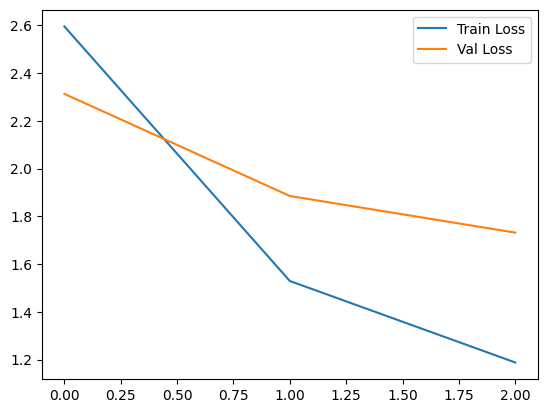

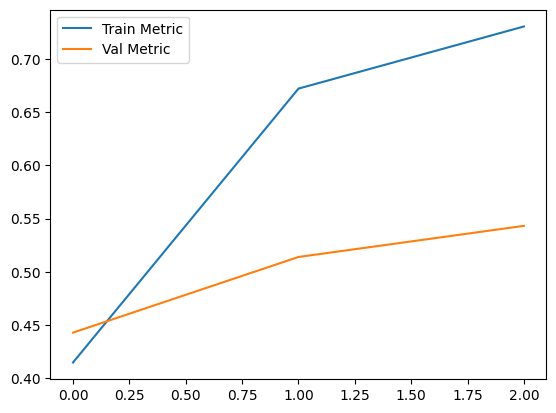

=== Дообучение всей сети на очищенных данных ===
Epoch 1/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.00it/s]


Train Loss: 0.2980 Train Metric: 0.9336
Val Loss: 0.3127 Val Metric: 0.9209
Epoch 2/5
----------


100%|██████████| 82/82 [00:41<00:00,  1.98it/s]


Train Loss: 0.0894 Train Metric: 0.9809
Val Loss: 0.2393 Val Metric: 0.9421
Epoch 3/5
----------


100%|██████████| 82/82 [00:40<00:00,  2.02it/s]


Train Loss: 0.0555 Train Metric: 0.9877
Val Loss: 0.2651 Val Metric: 0.9320
Epoch 4/5
----------


100%|██████████| 82/82 [00:41<00:00,  1.98it/s]


Train Loss: 0.0375 Train Metric: 0.9908
Val Loss: 0.2195 Val Metric: 0.9434
Epoch 5/5
----------


100%|██████████| 82/82 [00:41<00:00,  1.99it/s]

Train Loss: 0.0302 Train Metric: 0.9933
Val Loss: 0.2041 Val Metric: 0.9465


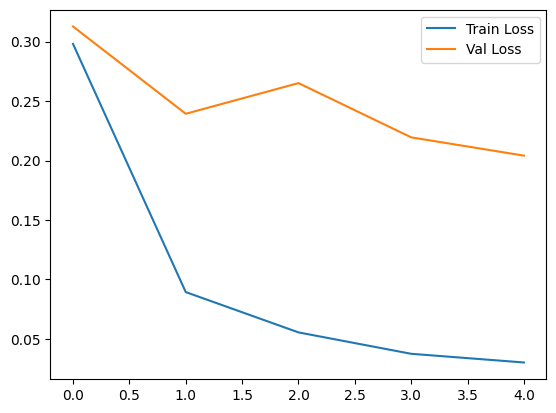

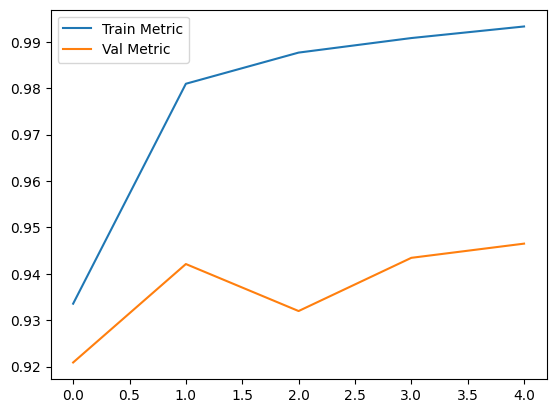

Веса resnet18_cleaned сохранены в /content/drive/MyDrive/dls/dls_part_1/weights/hw_5/resnet18_cleaned_weights.pth


In [86]:
from pathlib import Path

# Создаем чистую модель ResNet18 для обучения на очищенных данных
resnet18_cleaned = models.resnet18(weights=ResNet18_Weights.DEFAULT)
resnet18_cleaned.fc = nn.Linear(resnet18_cleaned.fc.in_features, len(label_encoder.classes_))
resnet18_cleaned = resnet18_cleaned.to(DEVICE)

resnet18_cleaned_weights_path = weights_folder / 'resnet18_cleaned_weights.pth'
FORCE_RETRAIN_CLEANED = False

if resnet18_cleaned_weights_path.exists() and not FORCE_RETRAIN_CLEANED:
    print(f"Загружаем сохраненные веса {resnet18_cleaned_weights_path}...")
    resnet18_cleaned.load_state_dict(torch.load(resnet18_cleaned_weights_path, map_location=DEVICE))
else:
    # Обучаем классификатор (замороженный backbone)
    for param in resnet18_cleaned.parameters():
        param.requires_grad = False
    for param in resnet18_cleaned.fc.parameters():
        param.requires_grad = True

    # Используем Weighted CrossEntropyLoss с предварительно рассчитанными весами классов
    criterion = nn.CrossEntropyLoss()
    optimizer_fc = torch.optim.AdamW(resnet18_cleaned.fc.parameters(), lr=1e-3, weight_decay=1e-2)

    print("=== Обучение классификатора на очищенных данных ===")
    train_model(resnet18_cleaned, loaders, criterion, optimizer_fc, f1_metric, n_epochs=3)

    # Размораживаем всю сеть и дообучаем с меньшим learning rate
    for param in resnet18_cleaned.parameters():
        param.requires_grad = True

    optimizer_full = torch.optim.AdamW(resnet18_cleaned.parameters(), lr=1e-4, weight_decay=1e-2)
    print("=== Дообучение всей сети на очищенных данных ===")
    train_model(resnet18_cleaned, loaders, criterion, optimizer_full, f1_metric, n_epochs=5)

    torch.save(resnet18_cleaned.state_dict(), resnet18_cleaned_weights_path)
    print(f"Веса resnet18_cleaned сохранены в {resnet18_cleaned_weights_path}")


In [87]:
predicted_numeric_labels = predict(resnet18_cleaned, test_loader)
predicted_text_labels = label_encoder.inverse_transform(predicted_numeric_labels)
my_submission = pd.DataFrame({'Id': [path.name for path in test_files], 'Expected': predicted_text_labels})

sub_filename = 'cleaned_weighted_adamw_resnet18_cnn_baseline.csv'

my_submission.to_csv(sub_filename, index=False)

Test mode...


100%|██████████| 16/16 [00:03<00:00,  4.62it/s]
